In [ ]:
# 1. Install dependencies
!pip install tensorflow tensorflow_datasets scikit-learn matplotlib seaborn -q


In [ ]:
# 2. Imports
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16, DenseNet121, MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

In [ ]:
# 3. Load Dataset (tf_flowers from TensorFlow Datasets)
(ds_train, ds_val, ds_test), ds_info = tfds.load(
    'tf_flowers',
    split=['train[:70%]', 'train[70%:85%]', 'train[85%:]'],
    with_info=True,
    as_supervised=True,
)
num_classes = ds_info.features['label'].num_classes
print("Flower classes:", num_classes)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.9ZFH58_3.0.1/tf_flowers-train.tfrecord*...:   0%|   …

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Flower classes: 5


In [ ]:
# 4. Preprocess Data
IMG_SIZE = 224
BATCH_SIZE = 32

def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE)) / 255.0
    return image, label

ds_train = ds_train.map(preprocess).shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
ds_val = ds_val.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
ds_test = ds_test.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


In [ ]:
# 5. Data Augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
])

In [ ]:
# 6. Function to build model
def build_model(base_model, num_classes, fine_tune_at=None):
    # Freeze layers before fine_tune_at
    if fine_tune_at:
        for layer in base_model.layers[:fine_tune_at]:
            layer.trainable = False
        for layer in base_model.layers[fine_tune_at:]:
            layer.trainable = True
    else:
        base_model.trainable = False  # Default: keep frozen

    model = models.Sequential([
        data_augmentation,
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])

    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)  # lower LR for fine-tuning
    model.compile(optimizer=optimizer,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model


In [ ]:
# 7. Callbacks
early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=3, verbose=1)


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# 8. Train and Evaluate Function
def train_and_evaluate(model, name):
    print(f"\n🚀 Training {name} ...")
    history = model.fit(
        ds_train,
        epochs=20,
        validation_data=ds_val,
        callbacks=[early_stop, reduce_lr],
        verbose=1
    )
    # Evaluate
    test_loss, test_acc = model.evaluate(ds_test)
    print(f"✅ {name} Test Accuracy: {test_acc:.4f}")

    # Predictions for Confusion Matrix & Report
    y_true, y_pred = [], []
    for images, labels in ds_test:
        preds = model.predict(images)
        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(preds, axis=1))

    print(f"\n📊 Classification Report for {name}:")
    print(classification_report(y_true, y_pred, target_names=[str(i) for i in range(num_classes)]))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

    # Extra Metrics
    precision = precision_score(y_true, y_pred, average="weighted")
    recall = recall_score(y_true, y_pred, average="weighted")
    f1 = f1_score(y_true, y_pred, average="weighted")

    print(f"📊 Metrics -> Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}")

    return history, test_acc, precision, recall, f1


In [ ]:
# 9. Build Models
mobilenet_base = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
mobilenet_model = build_model(mobilenet_base, num_classes, fine_tune_at=120)

vgg_base = VGG16(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
vgg_model = build_model(vgg_base, num_classes, fine_tune_at=None)

densenet_base = DenseNet121(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
densenet_model = build_model(densenet_base, num_classes, fine_tune_at=None)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step



🚀 Training MobileNetV2 ...
Epoch 1/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 101ms/step - accuracy: 0.9892 - loss: 0.0395 - val_accuracy: 0.9038 - val_loss: 0.3369 - learning_rate: 2.0000e-05
Epoch 2/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 95ms/step - accuracy: 0.9848 - loss: 0.0418 - val_accuracy: 0.9238 - val_loss: 0.2912 - learning_rate: 2.0000e-05
Epoch 3/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 94ms/step - accuracy: 0.9896 - loss: 0.0395 - val_accuracy: 0.9310 - val_loss: 0.2773 - learning_rate: 2.0000e-05
Epoch 4/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 92ms/step - accuracy: 0.9882 - loss: 0.0349 - val_accuracy: 0.9274 - val_loss: 0.2799 - learning_rate: 2.0000e-05
Epoch 5/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 95ms/step - accuracy: 0.9918 - loss: 0.0296 - val_accuracy: 0.9347 - val_loss: 0.2482 - learning_rate: 2.0000e-05
Epoch 6/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 95ms/step - accuracy: 0.9918 - loss: 0.0367 - val_accuracy: 0.9401 - val_loss: 0.2322 - learning_rate: 2.0000e-05
Epoch 7/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 

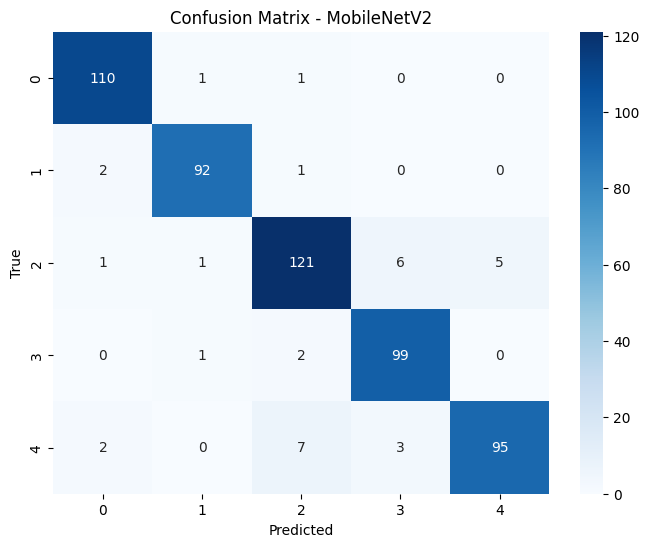

📊 Metrics -> Precision: 0.9402, Recall: 0.9400, F1: 0.9397

🚀 Training VGG16 ...
Epoch 1/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 157ms/step - accuracy: 0.7062 - loss: 0.8184 - val_accuracy: 0.7332 - val_loss: 0.7670 - learning_rate: 1.0000e-04
Epoch 2/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 20s 157ms/step - accuracy: 0.7131 - loss: 0.8298 - val_accuracy: 0.7350 - val_loss: 0.7553 - learning_rate: 1.0000e-04
Epoch 3/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 160ms/step - accuracy: 0.7202 - loss: 0.8038 - val_accuracy: 0.7441 - val_loss: 0.7455 - learning_rate: 1.0000e-04
Epoch 4/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 158ms/step - accuracy: 0.7390 - loss: 0.7859 - val_accuracy: 0.7368 - val_loss: 0.7359 - learning_rate: 1.0000e-04
Epoch 5/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 152ms/step - accuracy: 0.7187 - loss: 0.7749 - val_accuracy: 0.7423 - val_loss: 0.7244 - learning_rate: 1.0000e-04
Epoch 6/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 157ms/step - accuracy: 0.7239 - loss: 0.7713 - val_accuracy: 0.7387 - val_loss: 0.7232 - lea

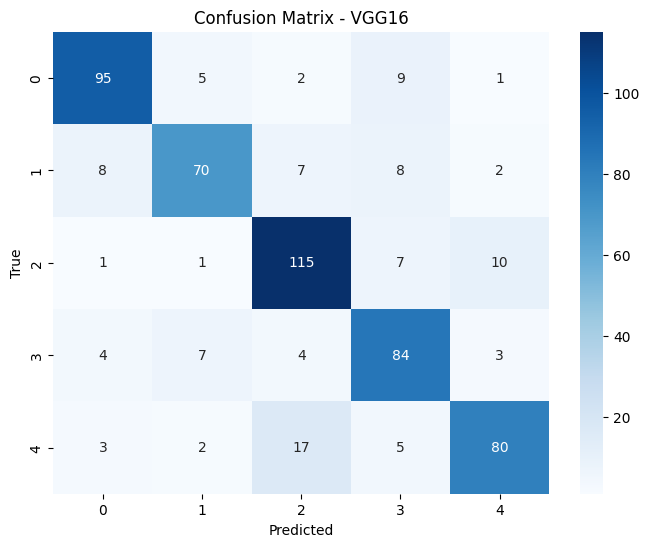

📊 Metrics -> Precision: 0.8097, Recall: 0.8073, F1: 0.8069

🚀 Training DenseNet121 ...
Epoch 1/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 15s 173ms/step - accuracy: 0.8863 - loss: 0.3438 - val_accuracy: 0.9002 - val_loss: 0.2744 - learning_rate: 1.0000e-04
Epoch 2/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 167ms/step - accuracy: 0.8833 - loss: 0.3270 - val_accuracy: 0.9002 - val_loss: 0.2700 - learning_rate: 1.0000e-04
Epoch 3/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 170ms/step - accuracy: 0.8862 - loss: 0.3365 - val_accuracy: 0.9038 - val_loss: 0.2745 - learning_rate: 1.0000e-04
Epoch 4/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 20s 166ms/step - accuracy: 0.8841 - loss: 0.3204 - val_accuracy: 0.9020 - val_loss: 0.2677 - learning_rate: 1.0000e-04
Epoch 5/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 21s 172ms/step - accuracy: 0.8783 - loss: 0.3361 - val_accuracy: 0.8966 - val_loss: 0.2641 - learning_rate: 1.0000e-04
Epoch 6/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 172ms/step - accuracy: 0.8887 - loss: 0.3027 - val_accuracy: 0.9147 - val_loss: 0.2622

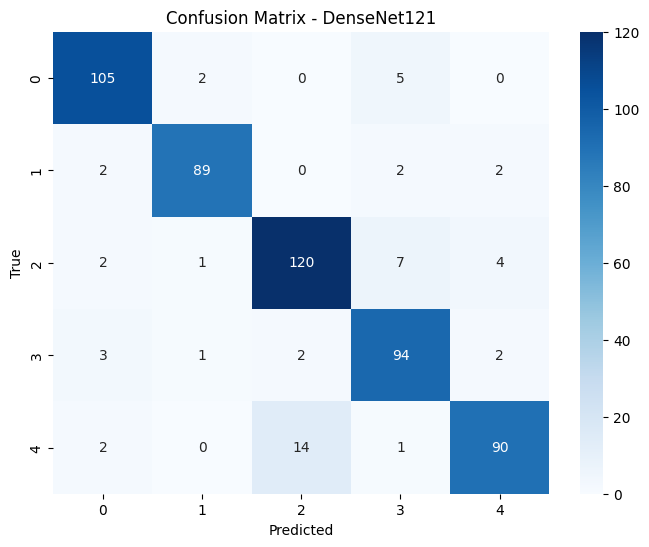

📊 Metrics -> Precision: 0.9064, Recall: 0.9055, F1: 0.9054


In [ ]:
history_mobilenet, acc_mobilenet, prec_mobilenet, rec_mobilenet, f1_mobilenet = train_and_evaluate(mobilenet_model, "MobileNetV2")
history_vgg, acc_vgg, prec_vgg, rec_vgg, f1_vgg = train_and_evaluate(vgg_model, "VGG16")
history_densenet, acc_densenet, prec_densenet, rec_densenet, f1_densenet = train_and_evaluate(densenet_model, "DenseNet121")


In [ ]:
# Create a DataFrame for results
import pandas as pd

results_df = pd.DataFrame({
    "Model": ["MobileNetV2", "VGG16", "DenseNet121"],
    "Accuracy": [acc_mobilenet, acc_vgg, acc_densenet],
    "Precision": [prec_mobilenet, prec_vgg, prec_densenet],
    "Recall": [rec_mobilenet, rec_vgg, rec_densenet],
    "F1-score": [f1_mobilenet, f1_vgg, f1_densenet]
})

print("\n📊 Final Model Comparison Table:")
print(results_df)



📊 Final Model Comparison Table:
         Model  Accuracy  Precision    Recall  F1-score
0  MobileNetV2  0.940000   0.940207  0.940000  0.939709
1        VGG16  0.807273   0.809739  0.807273  0.806942
2  DenseNet121  0.905455   0.906429  0.905455  0.905384


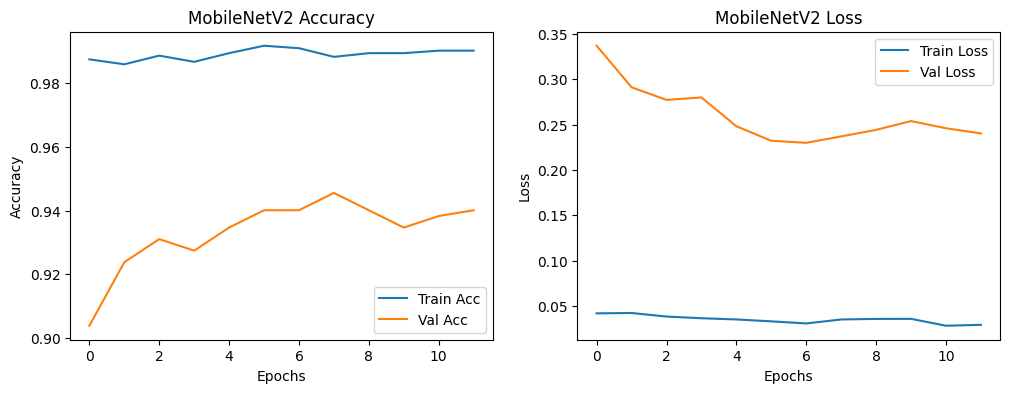

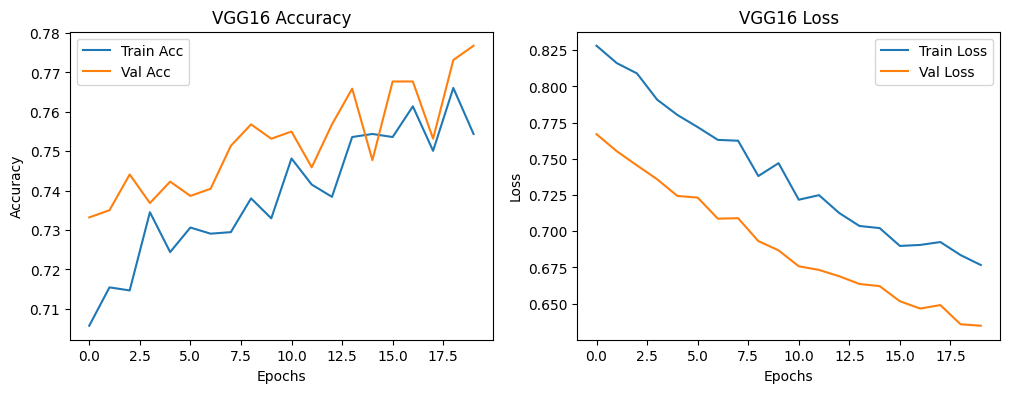

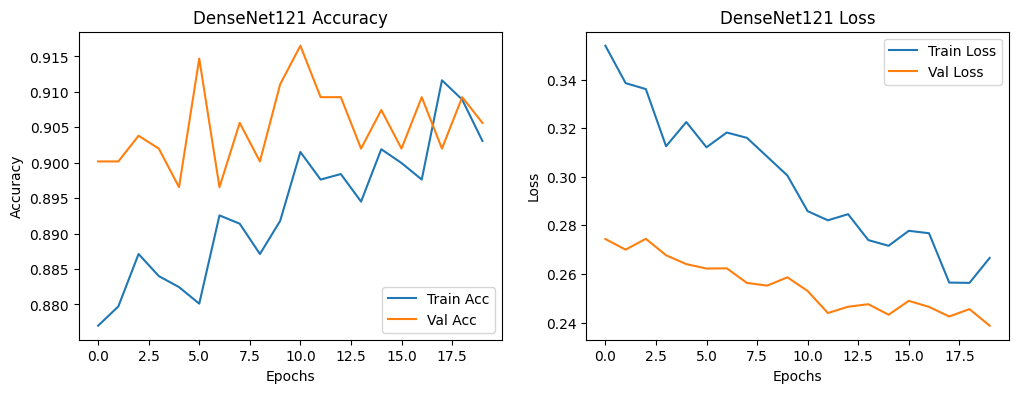

In [ ]:
# 12. Visualization - Accuracy & Loss Curves
def plot_training_curves(history, name):
    plt.figure(figsize=(12,4))
    # Accuracy
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label='Train Acc')
    plt.plot(history.history['val_accuracy'], label='Val Acc')
    plt.title(f"{name} Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    # Loss
    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f"{name} Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

plot_training_curves(history_mobilenet, "MobileNetV2")
plot_training_curves(history_vgg, "VGG16")
plot_training_curves(history_densenet, "DenseNet121")

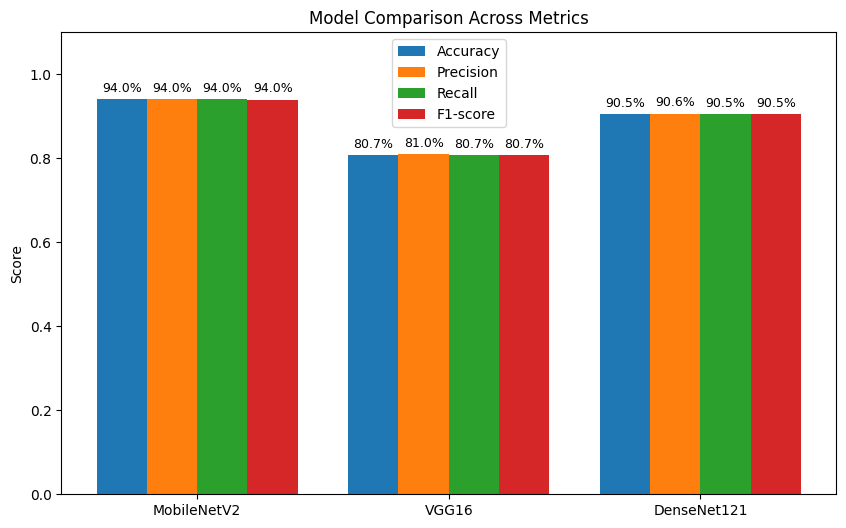

In [ ]:
# 13. Bar Chart Comparison with Percentage Labels
plt.figure(figsize=(10,6))
bar_width = 0.2
models = results_df["Model"]
x = np.arange(len(models))

# Plot bars
bars1 = plt.bar(x, results_df["Accuracy"], width=bar_width, label="Accuracy")
bars2 = plt.bar(x + bar_width, results_df["Precision"], width=bar_width, label="Precision")
bars3 = plt.bar(x + 2*bar_width, results_df["Recall"], width=bar_width, label="Recall")
bars4 = plt.bar(x + 3*bar_width, results_df["F1-score"], width=bar_width, label="F1-score")

# Add percentage labels on each bar
for bars in [bars1, bars2, bars3, bars4]:
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, height + 0.01,
                 f"{height*100:.1f}%", ha='center', va='bottom', fontsize=9)

# Formatting
plt.xticks(x + 1.5*bar_width, models)
plt.ylim(0,1.1)
plt.title("Model Comparison Across Metrics")
plt.ylabel("Score")
plt.legend()
plt.show()


In [ ]:
best_model_idx = results_df["Accuracy"].idxmax()
best_model = results_df.loc[best_model_idx, "Model"]
best_accuracy = results_df.loc[best_model_idx, "Accuracy"]

print(f"🏆 Best Model: {best_model} with Accuracy: {best_accuracy:.4f}")


🏆 Best Model: MobileNetV2 with Accuracy: 0.9400
